# Phase 2 – Analyse Exploratoire des Données
## Tâche 2.3 : Visualisations des profils d'étudiants à risque

**Projet :** Alerte précoce du décrochage universitaire  
**Objectif :** Créer des visualisations claires et professionnelles qui illustrent les profils d'étudiants les plus exposés au décrochage.

Ces graphiques s'appuient sur les résultats des tâches 2.1 et 2.2 (corrélations et associations).


## 1. Chargement des données enrichies et configuration

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Style global
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

# Chargement du dataset enrichi (créé en fin de Tâche 2.2)
DATA_PATH = Path("../dataset/processed/student_data_enriched.csv")
df = pd.read_csv(DATA_PATH)

# S'assurer que is_dropout existe
if "is_dropout" not in df.columns:
    df["is_dropout"] = (df["target"] == "Dropout").astype(int)

print(f"Dataset chargé : {df.shape[0]} étudiants × {df.shape[1]} variables")
print(f"Taux de décrochage global : {df['is_dropout'].mean()*100:.1f}%")
df.head()


Dataset chargé : 4424 étudiants × 43 variables
Taux de décrochage global : 32.1%


,marital_status,application_mode,application_order,course,daytime_evening_attendance,previous_qualification,previous_qualification_grade,nationality,mother_qualification,father_qualification,...,unemployment_rate,inflation_rate,gdp,target,is_dropout,success_rate_1st,success_rate_2nd,avg_grade,total_approved,grade_diff
0,1,17,5,171,1,1,122.0,1,19,12,...,10.8,1.4,1.74,Dropout,1,0.000000,0.000000,0.000000,0,0.000000
1,1,15,1,9254,1,1,160.0,1,1,3,...,13.9,-0.3,0.79,Graduate,0,1.000000,1.000000,13.833333,12,-0.333333
2,1,1,5,9070,1,1,122.0,1,37,37,...,10.8,1.4,1.74,Dropout,1,0.000000,0.000000,0.000000,0,0.000000
3,1,17,2,9773,1,1,122.0,1,38,37,...,9.4,-0.8,-3.12,Graduate,0,1.000000,0.833333,12.914286,11,-1.028571
4,2,39,1,8014,0,1,100.0,1,37,38,...,13.9,-0.3,0.79,Graduate,0,0.833333,1.000000,12.666667,11,0.666667


## 2. Vue d'ensemble de la variable cible

Répartition des trois statuts académiques et taux de décrochage.


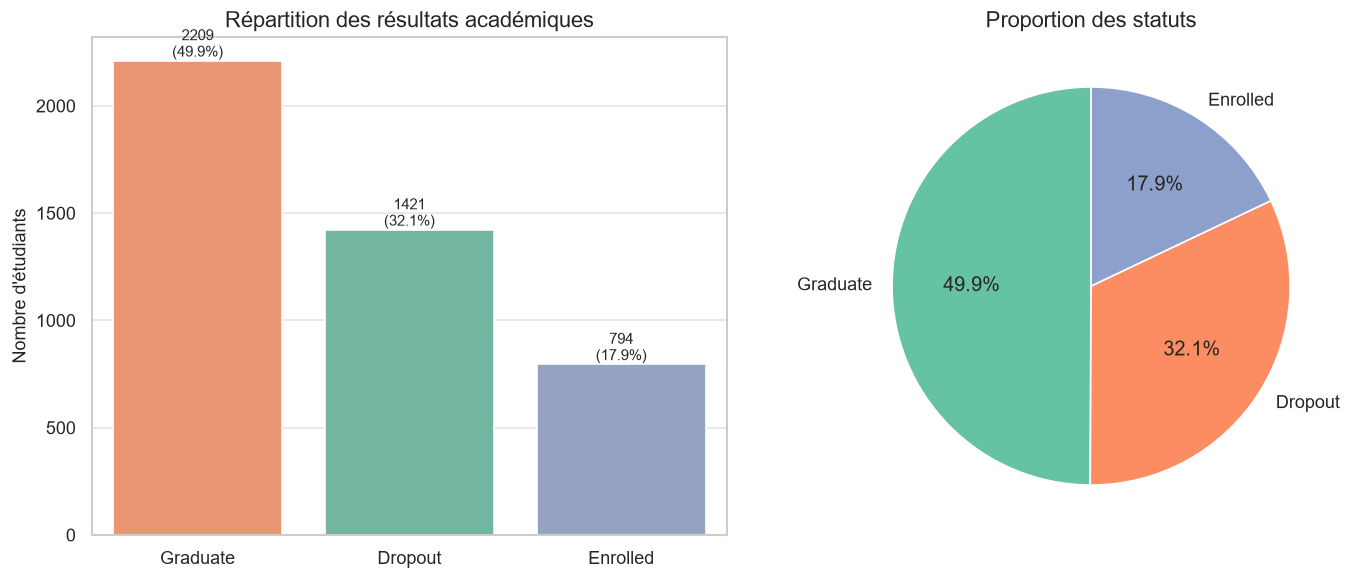

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# --- Countplot ---
order = df["target"].value_counts().index
ax1 = sns.countplot(data=df, x="target", hue="target", order=order, ax=axes[0], legend=False)
axes[0].set_title("Répartition des résultats académiques")
axes[0].set_xlabel("")
axes[0].set_ylabel("Nombre d'étudiants")

total = len(df)
for p in ax1.patches:
    h = p.get_height()
    ax1.annotate(f"{int(h)}\n({h/total*100:.1f}%)",
                 (p.get_x() + p.get_width()/2, h),
                 ha="center", va="bottom", fontsize=9)

# --- Pie chart ---
counts = df["target"].value_counts()
axes[1].pie(counts, labels=counts.index, autopct="%1.1f%%",
            startangle=90, colors=sns.color_palette("Set2"))
axes[1].set_title("Proportion des statuts")

plt.tight_layout()
plt.show()


## 3. Facteurs de risque financiers

Les analyses précédentes ont montré que les variables financières  
(`tuition_fees_up_to_date`, `scholarship_holder`, `debtor`) sont parmi les plus associées au décrochage.


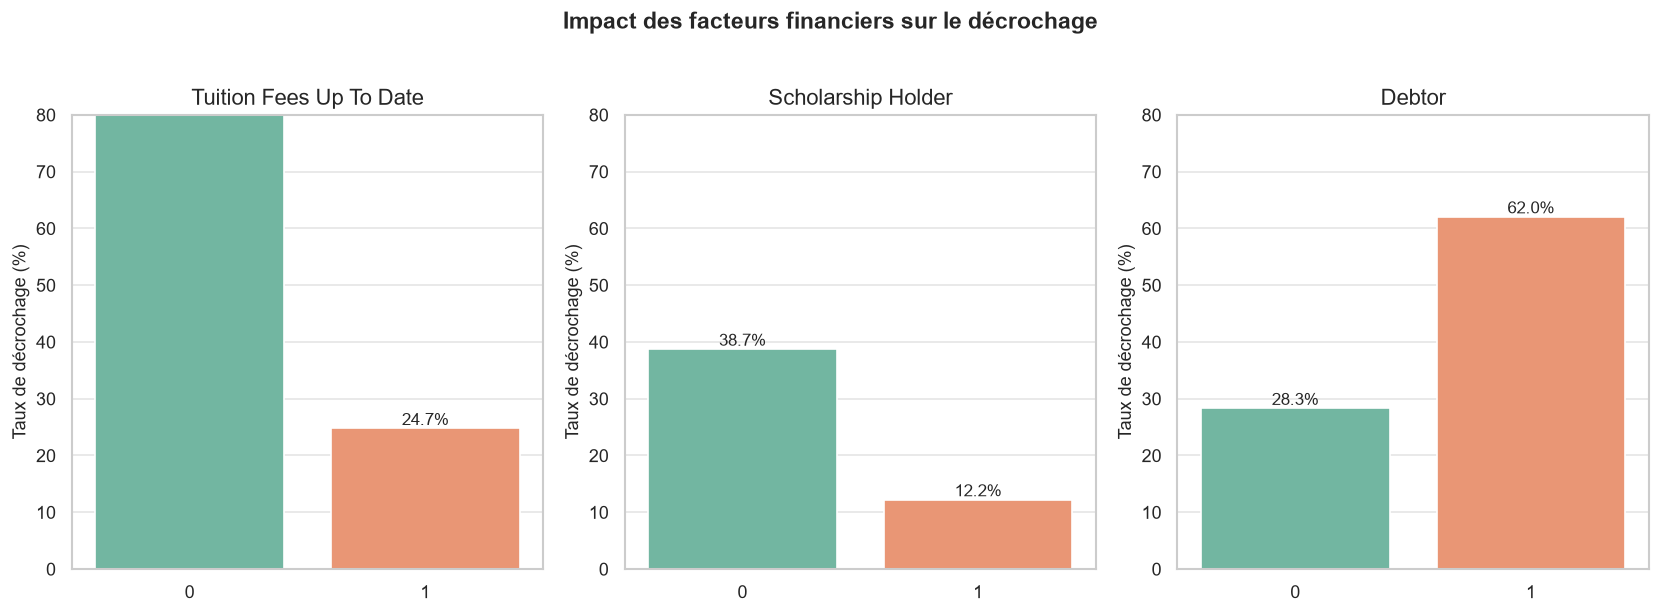

In [3]:
risk_financial = ["tuition_fees_up_to_date", "scholarship_holder", "debtor"]

fig, axes = plt.subplots(1, 3, figsize=(14, 5))

for i, col in enumerate(risk_financial):
    # Taux de décrochage par modalité
    rates = df.groupby(col, observed=True)["is_dropout"].mean().mul(100).reset_index()
    rates.columns = [col, "dropout_rate"]
    
    sns.barplot(data=rates, x=col, y="dropout_rate", hue=col,
                ax=axes[i], legend=False, palette="Set2")
    axes[i].set_title(col.replace("_", " ").title())
    axes[i].set_ylabel("Taux de décrochage (%)")
    axes[i].set_xlabel("")
    axes[i].set_ylim(0, 80)
    
    for p in axes[i].patches:
        h = p.get_height()
        axes[i].annotate(f"{h:.1f}%",
                         (p.get_x() + p.get_width()/2, h),
                         ha="center", va="bottom", fontsize=10)

plt.suptitle("Impact des facteurs financiers sur le décrochage", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


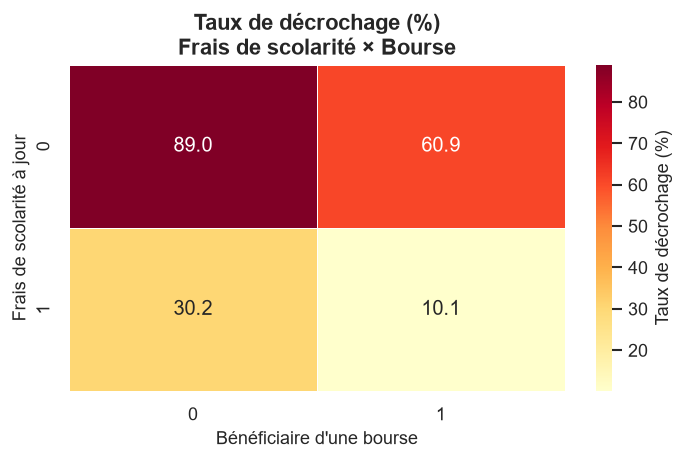

→ Le profil le plus à risque combine : frais non à jour + absence de bourse.


In [4]:
# Combinaison Tuition fees × Scholarship (profil le plus risqué)
pivot = df.groupby(["tuition_fees_up_to_date", "scholarship_holder"], observed=True)["is_dropout"]\
          .mean().mul(100).round(1).unstack()

plt.figure(figsize=(6, 4))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="YlOrRd", linewidths=0.6,
            cbar_kws={"label": "Taux de décrochage (%)"})
plt.title("Taux de décrochage (%)\nFrais de scolarité × Bourse", fontsize=13, fontweight="bold")
plt.xlabel("Bénéficiaire d'une bourse")
plt.ylabel("Frais de scolarité à jour")
plt.tight_layout()
plt.show()

print("→ Le profil le plus à risque combine : frais non à jour + absence de bourse.")


## 4. Performance académique selon le résultat

Les notes et le nombre d'unités validées sont les signaux les plus forts  
(corrélations négatives autour de -0.50 avec le décrochage).


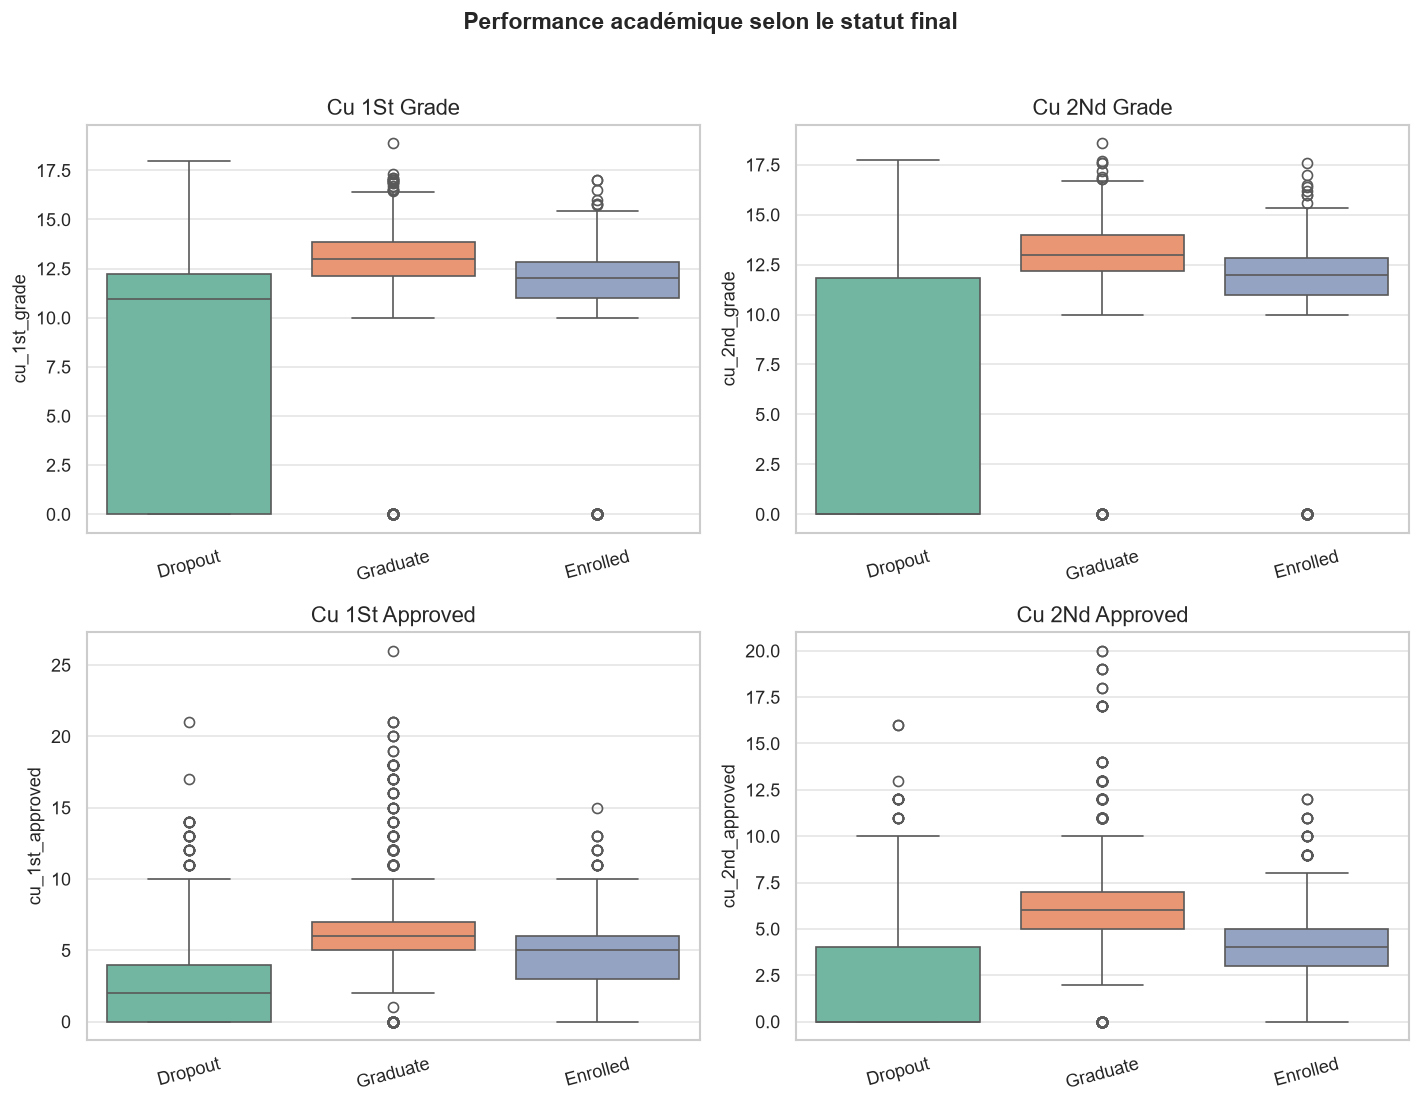

In [5]:
perf_cols = ["cu_1st_grade", "cu_2nd_grade", "cu_1st_approved", "cu_2nd_approved"]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes = axes.flatten()

for i, col in enumerate(perf_cols):
    sns.boxplot(data=df, x="target", y=col, hue="target",
                ax=axes[i], legend=False, palette="Set2")
    axes[i].set_title(col.replace("_", " ").title())
    axes[i].set_xlabel("")
    axes[i].tick_params(axis="x", rotation=15)

plt.suptitle("Performance académique selon le statut final", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


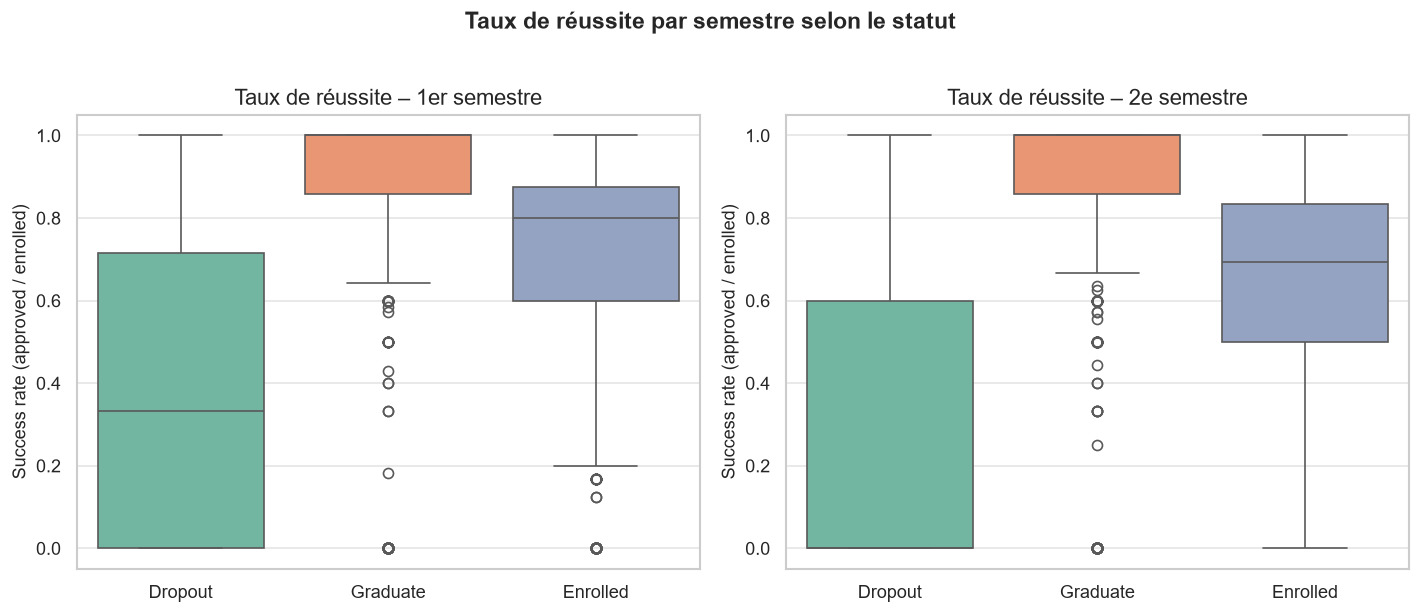

In [6]:
# Taux de réussite (features dérivées)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(data=df, x="target", y="success_rate_1st", hue="target",
            ax=axes[0], legend=False, palette="Set2")
axes[0].set_title("Taux de réussite – 1er semestre")
axes[0].set_ylabel("Success rate (approved / enrolled)")
axes[0].set_xlabel("")

sns.boxplot(data=df, x="target", y="success_rate_2nd", hue="target",
            ax=axes[1], legend=False, palette="Set2")
axes[1].set_title("Taux de réussite – 2e semestre")
axes[1].set_ylabel("Success rate (approved / enrolled)")
axes[1].set_xlabel("")

plt.suptitle("Taux de réussite par semestre selon le statut", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


## 5. Âge à l'inscription et autres facteurs démographiques


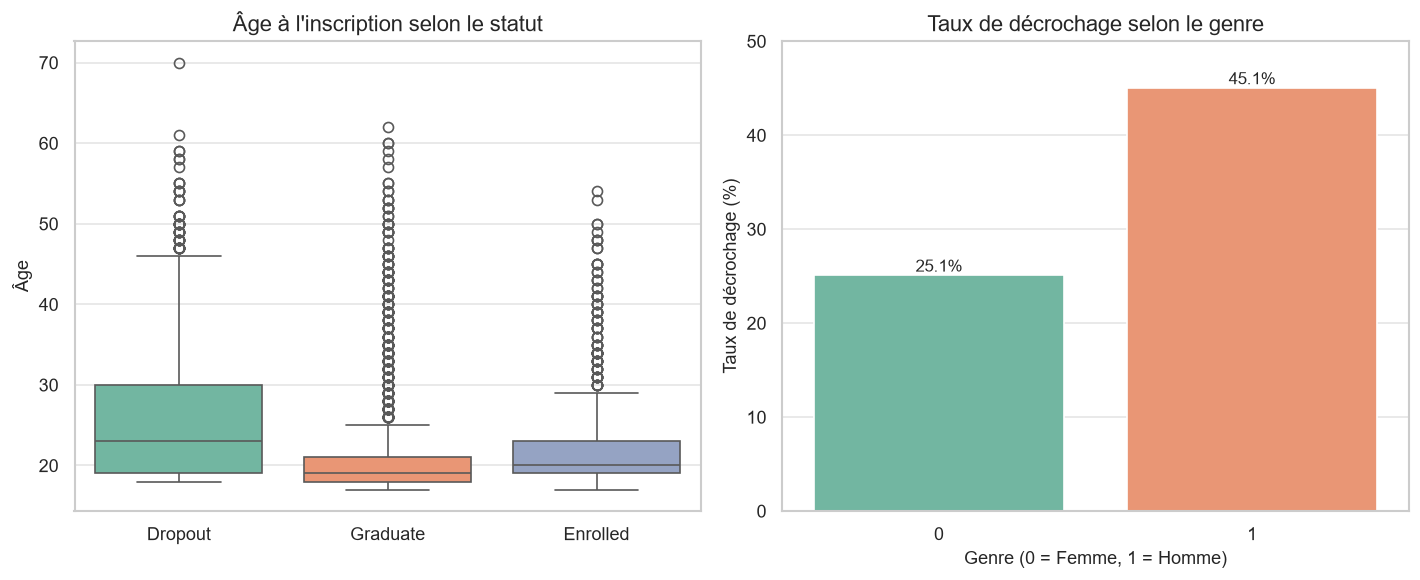

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Age distribution
sns.boxplot(data=df, x="target", y="age_at_enrollment", hue="target",
            ax=axes[0], legend=False, palette="Set2")
axes[0].set_title("Âge à l'inscription selon le statut")
axes[0].set_xlabel("")
axes[0].set_ylabel("Âge")

# Gender
gender_rates = df.groupby("gender", observed=True)["is_dropout"].mean().mul(100).reset_index()
sns.barplot(data=gender_rates, x="gender", y="is_dropout", hue="gender",
            ax=axes[1], legend=False, palette="Set2")
axes[1].set_title("Taux de décrochage selon le genre")
axes[1].set_ylabel("Taux de décrochage (%)")
axes[1].set_xlabel("Genre (0 = Femme, 1 = Homme)")
axes[1].set_ylim(0, 50)

for p in axes[1].patches:
    h = p.get_height()
    axes[1].annotate(f"{h:.1f}%", (p.get_x() + p.get_width()/2, h),
                     ha="center", va="bottom", fontsize=10)

plt.tight_layout()
plt.show()


## 6. Profil synthétique de l'étudiant à risque

Comparaison côte-à-côte des caractéristiques moyennes  
entre les étudiants qui décrochent et ceux qui réussissent.


In [8]:
# Sélection des variables les plus discriminantes
profile_vars = [
    "age_at_enrollment",
    "admission_grade",
    "cu_1st_grade", "cu_2nd_grade",
    "cu_1st_approved", "cu_2nd_approved",
    "success_rate_1st", "success_rate_2nd",
    "avg_grade", "total_approved"
]
profile_vars = [c for c in profile_vars if c in df.columns]

profile = df.groupby("is_dropout")[profile_vars].mean().T
profile.columns = ["Non-Dropout (0)", "Dropout (1)"]
profile["Différence"] = profile["Dropout (1)"] - profile["Non-Dropout (0)"]

print("Profil moyen – Étudiants qui décrochent vs les autres :")
display(profile.round(2))


Profil moyen – Étudiants qui décrochent vs les autres :


,Non-Dropout (0),Dropout (1),Différence
age_at_enrollment,21.94,26.07,4.13
admission_grade,127.93,124.96,-2.97
cu_1st_grade,12.24,7.26,-4.99
cu_2nd_grade,12.28,5.90,-6.38
cu_1st_approved,5.73,2.55,-3.17
cu_2nd_approved,5.62,1.94,-3.68
success_rate_1st,0.85,0.38,-0.46
success_rate_2nd,0.83,0.29,-0.54
avg_grade,12.26,6.58,-5.68
total_approved,11.34,4.49,-6.85


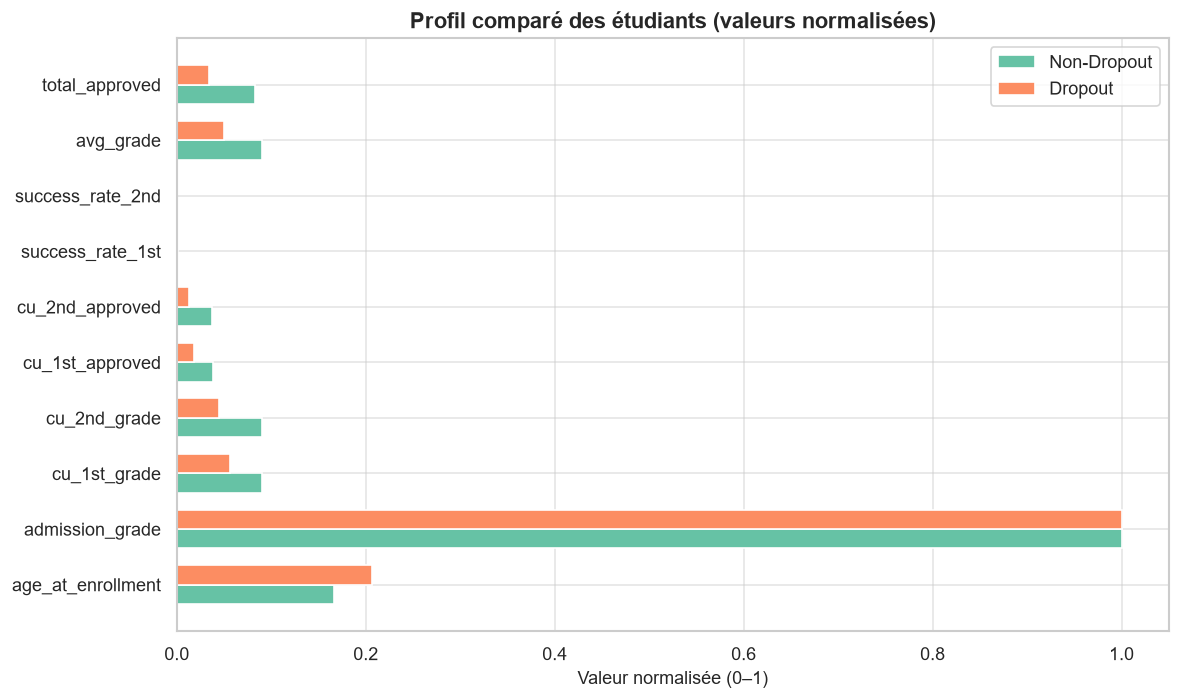

→ Les barres oranges (Dropout) sont nettement plus basses sur les indicateurs de performance académique.


In [9]:
# Visualisation du profil (radar-like bar comparison)
profile_plot = profile[["Non-Dropout (0)", "Dropout (1)"]].copy()

# Normalisation min-max pour pouvoir comparer sur la même échelle
profile_norm = (profile_plot - profile_plot.min()) / (profile_plot.max() - profile_plot.min())

fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(len(profile_norm))
width = 0.35

bars1 = ax.barh(x - width/2, profile_norm["Non-Dropout (0)"], width, label="Non-Dropout", color="#66c2a5")
bars2 = ax.barh(x + width/2, profile_norm["Dropout (1)"], width, label="Dropout", color="#fc8d62")

ax.set_yticks(x)
ax.set_yticklabels(profile_norm.index)
ax.set_xlabel("Valeur normalisée (0–1)")
ax.set_title("Profil comparé des étudiants (valeurs normalisées)", fontsize=13, fontweight="bold")
ax.legend()
plt.tight_layout()
plt.show()

print("→ Les barres oranges (Dropout) sont nettement plus basses sur les indicateurs de performance académique.")


## 7. Synthèse visuelle des principaux facteurs de risque


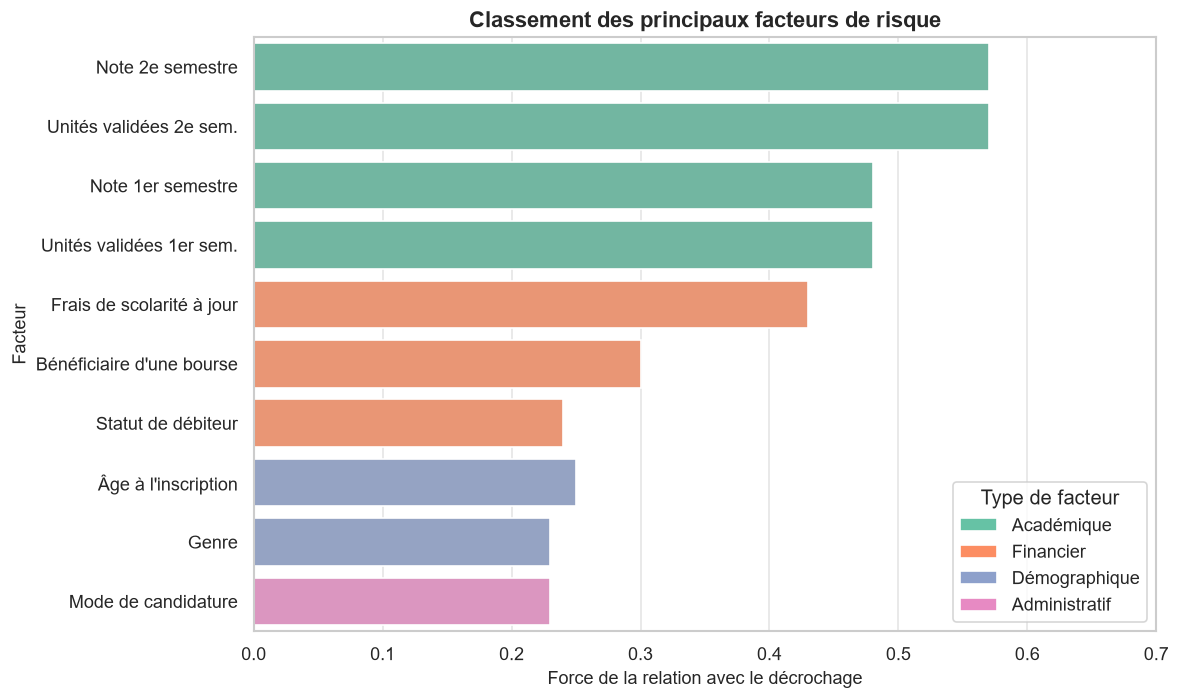

In [10]:
# Ranking des facteurs (basé sur les résultats de la Tâche 2.2)
factors = pd.DataFrame({
    "Facteur": [
        "Note 2e semestre",
        "Unités validées 2e sem.",
        "Note 1er semestre",
        "Unités validées 1er sem.",
        "Frais de scolarité à jour",
        "Bénéficiaire d'une bourse",
        "Statut de débiteur",
        "Âge à l'inscription",
        "Genre",
        "Mode de candidature"
    ],
    "Importance": [0.57, 0.57, 0.48, 0.48, 0.43, 0.30, 0.24, 0.25, 0.23, 0.23],
    "Type": ["Académique", "Académique", "Académique", "Académique",
             "Financier", "Financier", "Financier",
             "Démographique", "Démographique", "Administratif"]
})

plt.figure(figsize=(10, 6))
colors = {"Académique": "#66c2a5", "Financier": "#fc8d62",
          "Démographique": "#8da0cb", "Administratif": "#e78ac3"}
bar_colors = [colors[t] for t in factors["Type"]]

sns.barplot(data=factors, y="Facteur", x="Importance", palette=bar_colors, hue="Facteur", legend=False)
plt.xlabel("Force de la relation avec le décrochage")
plt.title("Classement des principaux facteurs de risque", fontsize=13, fontweight="bold")
plt.xlim(0, 0.7)

# Légende manuelle
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=c, label=l) for l, c in colors.items()]
plt.legend(handles=legend_elements, title="Type de facteur", loc="lower right")
plt.tight_layout()
plt.show()


## 8. Conclusions de la Tâche 2.3

### Profil type de l'étudiant à risque élevé

Un étudiant présente un risque nettement plus élevé de décrocher lorsqu'il cumule plusieurs des caractéristiques suivantes :

- **Performance académique faible** dès le premier semestre (notes basses + peu d'unités validées)
- **Difficultés financières** : frais de scolarité non à jour, absence de bourse, statut de débiteur
- **Âge plus élevé** à l'inscription
- Certaines filières et modes d'admission sont également plus exposés

### Points clés pour la suite du projet

- Les variables académiques (notes + unités validées) sont les plus discriminantes → elles devront être prioritaires dans le modèle.
- Les variables financières apportent une information complémentaire importante.
- Les indicateurs macroéconomiques et certaines variables démographiques (nationalité, besoins éducatifs spéciaux) sont peu informatifs.
